# Data Collection and Exploration

## I. Data Collection

### 1. Subject

- The dataset represents ten years (1999 - 2008) of clinical care at 130 US hospitals and integrated delivery network. 
- Each row concerns hospital records of patients diagnosed with diabetes, who underwent laboratory, medication and stayed up to 14 days. Note that a record relates to **a hospital encounter**, not a patient, which means a patient can have two or more records depending on how many times they come to the hospital.
- The problem is to predict the early readmission of the patient within 30 days of discharge. This reflects a real-world context: Hospital readmissions not only increase the managing costs for the hospitals but also impact the morbidity and mortality of the patients, who may face complications associated with diabetes.
- Therefore, determining the most likely patients to be readmitted can help the hospitals to focus on them.

### 2. Source
- The dataset originates from **UCI Machine Learning Repository, “Diabetes 130-US Hospitals for Years 1999-2008”**. Link: https://doi.org/10.24432/C5230J. 
- The original source is from the **Health Facts database**, a national data warehouse that collects comprehensive clinical records across hospitals throughout the United States, and is then extracted and processed by the authors.
- **Authors**: Beata Strack, Jonathan P. DeShazo, Chris Gennings, Juan L. Olmo, Sebastian Ventura, Krzysztof J. Cios, and John N. Clore.
- **Publication date**: 5/2/2014

### 3. License
- This dataset is licensed under a [Creative Commons Attribution 4.0 International](https://creativecommons.org/licenses/by/4.0/legalcode) (CC BY 4.0) license.
- This allows for the sharing and adaptation of the datasets for any purpose, provided that the appropriate credit is given.

### 4. Collection method
- The dataset is the clinical records of the patients collected from 130 US hospitals, not a survey.
- **Population**: Diabetic patients from 130 US hospitals and integrated delivery networks.
- **Period**: 10 years (1999 - 2008)
- **Additional information**: According to the authors, the information was extracted from the database for encounters that satisfied the following criteria:
    - It is an inpatient encounter.
    - It is an diabetic encounter, that is, one during which any kind of diabetes was entered into the system as a diagnosis.
    - The length of stay was at least 1 day and at most 14 days.
    - Laboratory tests were performed during the encounter.
    - Medications were administered during the encounter.
- **Limitations and biases**: 
    - The dataset is quite outdated (1999-2008) and it only records data from **US hospitals**.
    - The above criteria of the authors removed a subset of records from the dataset.
    - There are a lot of missing values, and the meaning of some features have to be looked up in `IDS_mapping.csv`

### 5. Motivation
- **A real and costly problem**: Hospital readmissions are expensive for hospitals, insurers and patients, and they are a common indicator of care quality. In the US, the Hospital Readmissions Reduction Program even penalises hospitals with high readmission rates. Diabetic patients are a high-risk group because they often have comorbidities (circulatory, respiratory diseases) and take many medications.
- **Suitable for both analysis and machine learning**: The dataset contains more than 100,000 rows with 47 features, so analyzing the insights would be challenging enough for this project. Moreover, the data is still missing, so it needs real preprocessing before being fed to ML models.

## II. Data Exploration

### 0. Import Libraries

In [19]:
%matplotlib inline

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent))  # project root, so that `src` can be imported
from src.data_utils import (RAW_DIR, load_raw, load_id_mapping, overview_table, missing_table,
                            numeric_summary, categorical_summary, icd9_group, readmission_rate,
                            ID_COLUMNS, UNKNOWN_ID_CODES, EXPIRED_OR_HOSPICE_CODES)

pd.set_option("display.max_columns", 60)
plt.rcParams["figure.dpi"] = 100

### 1. First look at the raw dataset

In [20]:
raw = pd.read_csv(RAW_DIR / "diabetic_data.csv", low_memory=False)
print(f"Number of rows: {raw.shape[0]}")
print(f"Number of columns: {raw.shape[1]}")
raw.head(10)

Number of rows: 101766
Number of columns: 50


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO
5,35754,82637451,Caucasian,Male,[50-60),?,2,1,2,3,?,?,31,6,16,0,0,0,414,411,250,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Yes,>30
6,55842,84259809,Caucasian,Male,[60-70),?,3,1,2,4,?,?,70,1,21,0,0,0,414,411,V45,7,NaN,NaN,Steady,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO
7,63768,114882984,Caucasian,Male,[70-80),?,1,1,7,5,?,?,73,0,12,0,0,0,428,492,250,8,NaN,NaN,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,>30
8,12522,48330783,Caucasian,Female,[80-90),?,2,1,4,13,?,?,68,2,28,0,0,0,398,427,38,8,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO
9,15738,63555939,Caucasian,Female,[90-100),?,3,3,4,12,?,InternalMedicine,33,3,18,0,0,0,434,198,486,8,NaN,NaN,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [21]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

With the default settings, pandas reports missing values only in these columns:

In [22]:
na_default = raw.isna().sum()
na_default[na_default > 0]

max_glu_serum    96420
A1Cresult        84748
dtype: int64

pandas reported `NaN` in `max_glu_serum` and `A1Cresult`. To see what was actually written in the file, we load it as plain text, with no automatic NaN conversion and count the values:

In [23]:
as_text = pd.read_csv(RAW_DIR / "diabetic_data.csv", keep_default_na=False, dtype=str)
for col in na_default[na_default > 0].index:
    print(col, as_text[col].value_counts().to_dict())

max_glu_serum {'None': 96420, 'Norm': 2597, '>200': 1485, '>300': 1264}
A1Cresult {'None': 84748, '>8': 8216, 'Norm': 4990, '>7': 3812}


However, as we observe in some first records, there are a lot of missing values that is hidden as text such as **"?"**. Therefore, we count, in every text column, values that look like placeholders.

First, we count in the **columns with few distince values** by printing all of their values and read them.

In [24]:
is_number = as_text.apply(lambda s: s.str.fullmatch(r"-?\d+").all())
text_cols = is_number[~is_number].index
few_values = [c for c in text_cols if as_text[c].nunique() <= 30]
many_values = [c for c in text_cols if c not in few_values]
print(f"{len(text_cols)} text columns: {len(few_values)} with <= 30 values, {len(many_values)} with more: {many_values}\n")
for col in few_values:
    print(col, as_text[col].value_counts().to_dict())

37 text columns: 33 with <= 30 values, 4 with more: ['medical_specialty', 'diag_1', 'diag_2', 'diag_3']

race {'Caucasian': 76099, 'AfricanAmerican': 19210, '?': 2273, 'Hispanic': 2037, 'Other': 1506, 'Asian': 641}
gender {'Female': 54708, 'Male': 47055, 'Unknown/Invalid': 3}
age {'[70-80)': 26068, '[60-70)': 22483, '[50-60)': 17256, '[80-90)': 17197, '[40-50)': 9685, '[30-40)': 3775, '[90-100)': 2793, '[20-30)': 1657, '[10-20)': 691, '[0-10)': 161}
weight {'?': 98569, '[75-100)': 1336, '[50-75)': 897, '[100-125)': 625, '[125-150)': 145, '[25-50)': 97, '[0-25)': 48, '[150-175)': 35, '[175-200)': 11, '>200': 3}
payer_code {'?': 40256, 'MC': 32439, 'HM': 6274, 'SP': 5007, 'BC': 4655, 'MD': 3532, 'CP': 2533, 'UN': 2448, 'CM': 1937, 'OG': 1033, 'PO': 592, 'DM': 549, 'CH': 146, 'WC': 135, 'OT': 95, 'MP': 79, 'SI': 55, 'FR': 1}
max_glu_serum {'None': 96420, 'Norm': 2597, '>200': 1485, '>300': 1264}
A1Cresult {'None': 84748, '>8': 8216, 'Norm': 4990, '>7': 3812}
metformin {'No': 81778, 'Stead

Next, we count in the columns with more distinct values by checking the format with regex. For example, diagnoses are ICD-9 codes (digits, or `V..` / `E..` codes); medical specialities are words.

In [25]:
icd9_pattern = r"\d{1,3}(\.\d+)?|V\d{2}(\.\d+)?|E\d{3}(\.\d+)?"
for col in ["diag_1", "diag_2", "diag_3"]:
    unexpected = as_text.loc[~as_text[col].str.fullmatch(icd9_pattern), col]
    print(col, "values not matching ICD-9:", unexpected.value_counts().to_dict())

unexpected = as_text.loc[~as_text["medical_specialty"].str.fullmatch(r"[A-Za-z/&\-]+"), "medical_specialty"]
print("medical_specialty values that are not words:", unexpected.value_counts().to_dict())

diag_1 values not matching ICD-9: {'?': 21}
diag_2 values not matching ICD-9: {'?': 358}
diag_3 values not matching ICD-9: {'?': 1423}
medical_specialty values that are not words: {'?': 49949}


Check hidden variants of the same label (extra spaces or different case):

In [26]:
for col in text_cols:
    s = as_text[col]
    if (s != s.str.strip()).any():
        print("extra spaces in", col)
    if s.str.lower().nunique() != s.nunique():
        print("case variants in", col)
print("check done")

check done


Finally, in **numerical columns**, we check placeholders such as `-1`, `0` or `999` would show up in the min/max

In [27]:
raw.select_dtypes(include="number").agg(["min", "max"]).T

,min,max
encounter_id,12522,443867222
patient_nbr,135,189502619
admission_type_id,1,8
discharge_disposition_id,1,28
admission_source_id,1,25
time_in_hospital,1,14
num_lab_procedures,1,132
num_procedures,0,6
num_medications,1,81
number_outpatient,0,42


The numeric code columns can also hide unknown values. Their meaning is in `IDS_mapping.csv`:

In [28]:
id_maps = load_id_mapping()
for col in ID_COLUMNS:
    unknown = id_maps[col][id_maps[col].str.contains("NULL|Not Available|Not Mapped|Unknown/Invalid")]
    print(f"{col}: unknown codes {unknown.index.tolist()} -> {raw[col].isin(unknown.index).sum():,} rows")

admission_type_id: unknown codes [5, 6, 8] -> 10,396 rows
discharge_disposition_id: unknown codes [18, 25, 26] -> 4,680 rows
admission_source_id: unknown codes [9, 15, 17, 20, 21] -> 7,067 rows


**After all those above work**, our group can have some first look about the dataset:
- `?` is the real missing marker, which appears in many features (e.g. `weight`, `payer_code`, `medical_specialty`, `race`, `diag_*`)
- The NaN that pandas created come from the string `None`, which mean *test not performed*, not a missing value.
- `gender` has `Unknown/Invalid`, and the id columns have codes meaning `NULL`/`NotAvailable`/`Not Mapped`.
- No extra spaces, no case variants in the dataset, and the min/max of the numerical columns are plausible.

### 2. Reload with the correct missing-value markers

Based on the above insights, we load the file again to read the file with `keep_default_na=False`, `na_values=["?"]`, and also counts `"Unknown/Invalid` and the unknown id codes as **missing values**. From here on we work with this version.

In [29]:
df = load_raw()
print("NaN per column after reloading:")
print(df.isna().sum()[lambda s: s > 0].to_dict())

NaN per column after reloading:
{'race': 2273, 'weight': 98569, 'payer_code': 40256, 'medical_specialty': 49949, 'diag_1': 21, 'diag_2': 358, 'diag_3': 1423}


In [30]:
print(f"Distinct encounters: {df['encounter_id'].nunique():,}")
print(f"Distinct patients  : {df['patient_nbr'].nunique():,}")
encounters_per_patient = df["patient_nbr"].value_counts()
print(f"Patients with more than one encounter: {(encounters_per_patient > 1).sum():,}")
print(f"Max encounters for one patient       : {encounters_per_patient.max()}")

Distinct encounters: 101,766
Distinct patients  : 71,518
Patients with more than one encounter: 16,773
Max encounters for one patient       : 40


In [31]:
print("Fully duplicated rows          :", df.duplicated().sum())
print("Duplicated rows without the IDs:", df.drop(columns=["encounter_id", "patient_nbr"]).duplicated().sum())
print("Completely empty rows          :", df.isna().all(axis=1).sum())

Fully duplicated rows          : 0
Duplicated rows without the IDs: 0
Completely empty rows          : 0


In [32]:
overview_table(df)

,dtype,n_unique,n_missing,pct_missing,examples
encounter_id,int64,101766,0,0.00,"[2278392, 149190, 64410, 500364]"
patient_nbr,int64,71518,0,0.00,"[8222157, 55629189, 86047875, 82442376]"
race,object,5,2273,2.23,"[Caucasian, AfricanAmerican, Other, Asian]"
gender,object,3,0,0.00,"[Female, Male, Unknown/Invalid]"
age,object,10,0,0.00,"[[0-10), [10-20), [20-30), [30-40)]"
weight,object,9,98569,96.86,"[[75-100), [50-75), [0-25), [100-125)]"
admission_type_id,int64,8,0,0.00,"[6, 1, 2, 3]"
discharge_disposition_id,int64,26,0,0.00,"[25, 1, 3, 6]"
admission_source_id,int64,17,0,0.00,"[1, 7, 2, 4]"
time_in_hospital,int64,14,0,0.00,"[1, 3, 2, 4]"


Columns are grouped by role so that the following sections can go deep on the relevant ones and summarise the rest:

In [33]:
id_cols = ["encounter_id", "patient_nbr"]
target_col = "readmitted"
numeric_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
                "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
code_cols = ID_COLUMNS                       # numeric codes that are really categories
diag_cols = ["diag_1", "diag_2", "diag_3"]   # ICD-9 codes
medication_cols = list(df.loc[:, "metformin":"metformin-pioglitazone"].columns)
categorical_cols = [c for c in df.columns
                    if c not in id_cols + [target_col] + numeric_cols + code_cols + diag_cols + medication_cols]
print("Numerical  :", numeric_cols)
print("Categorical:", categorical_cols)
print("Medications:", len(medication_cols), "columns")

Numerical  : ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
Categorical: ['race', 'gender', 'age', 'weight', 'payer_code', 'medical_specialty', 'max_glu_serum', 'A1Cresult', 'change', 'diabetesMed']
Medications: 23 columns


**Observations:**
- The dataset has **101,766 rows and 50 columns**. One row is one **inpatient encounter** of a diabetic patient, not one patient: there are only **71,518 distinct patients**, and **16,773 patients** have more than one encounter (up to 40). Rows of the same patient are therefore not independent.
- There are **no duplicated rows** (even after removing the two IDs) and **no empty rows**, so no row needs to be removed at this step.
- Column types need some conversion:
    - `encounter_id`, `patient_nbr` are identifiers, not features.
    - `admission_type_id`, `discharge_disposition_id`, `admission_source_id` are stored as integers but are **categorical codes**; we translate them with `IDS_mapping.csv`.
    - `age` and `weight` are **intervals stored as text** (e.g. `[70-80)`), which can be treated as ordered categories.
    - `diag_1`, `diag_2`, `diag_3` have **700+ ICD-9 codes each**, too many to use directly, so they will be grouped into disease groups.
- Some columns are candidates to drop or handle specially: `weight` (96.9% missing), `medical_specialty` (49.1%), `payer_code` (39.6%), and several medication columns that almost never change.
- The target `readmitted` has 3 values (`NO`, `>30`, `<30`). 

### 3. Numerical columns

In [34]:
numeric_summary(df, numeric_cols)

,mean,median,std,min,max,skew,iqr_outliers,z_outliers
time_in_hospital,4.40,4.0,2.99,1.0,14.0,1.13,2252.0,1042.0
num_lab_procedures,43.10,44.0,19.67,1.0,132.0,-0.24,143.0,43.0
num_procedures,1.34,1.0,1.71,0.0,6.0,1.32,4954.0,0.0
num_medications,16.02,15.0,8.13,1.0,81.0,1.33,2557.0,1361.0
number_outpatient,0.37,0.0,1.27,0.0,42.0,8.83,16739.0,1457.0
number_emergency,0.20,0.0,0.93,0.0,76.0,22.86,11383.0,1664.0
number_inpatient,0.64,0.0,1.26,0.0,21.0,3.61,7049.0,2016.0
number_diagnoses,7.42,8.0,1.93,1.0,16.0,-0.88,281.0,281.0


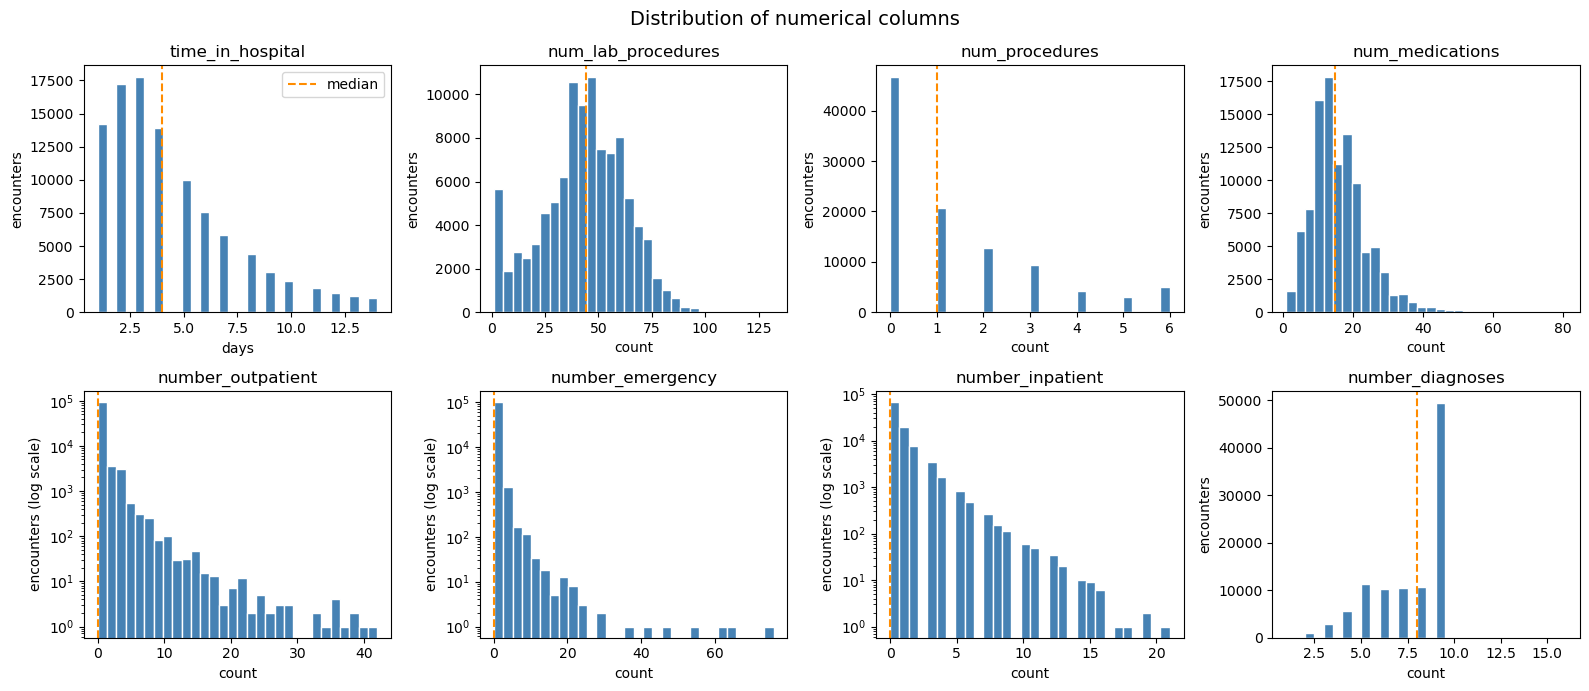

In [35]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), numeric_cols):
    ax.hist(df[col], bins=30, color="steelblue", edgecolor="white")
    ax.axvline(df[col].median(), color="darkorange", linestyle="--", label="median")
    ax.set_title(col)
    ax.set_xlabel("count" if col.startswith(("num_", "number_")) else "days")
    ax.set_ylabel("encounters")
    if col in ["number_outpatient", "number_emergency", "number_inpatient"]:
        ax.set_yscale("log")   # very right-skewed: log scale makes the tail visible
        ax.set_ylabel("encounters (log scale)")
axes[0, 0].legend()
fig.suptitle("Distribution of numerical columns", fontsize=14)
plt.tight_layout()
plt.show()

**Observations:**
- **All values are plausible**: no negative values or placeholders such as `-1` or `999`. `time_in_hospital` ranges from 1 to 14 days, which matches the selection criteria of the dataset.
- **Hospital stay variables**: `time_in_hospital` (median 4 days) and `num_medications` (median 15) are right-skewed (skew about 1.1–1.3). `num_lab_procedures` is roughly symmetric (median 44) but has a small peak at very low values (about 5.5% of encounters have 5 or fewer lab procedures). `num_procedures` is mostly 0.
- **Visit history** (`number_outpatient`, `number_emergency`, `number_inpatient`) is **zero-inflated and extremely right-skewed** (skew 8.8, 22.9 and 3.6). Only 16.4%, 11.2% and 33.5% of encounters have at least one previous visit of each type.
- `number_diagnoses` has a strong peak at **9** (49,474 encounters) and only 135 encounters above 9. This suggests that most records stored at most 9 diagnoses, so values above 9 should be interpreted with care.

Outliers by the IQR rule are checked against plausible clinical ranges: are they data entry errors or real, very sick patients?

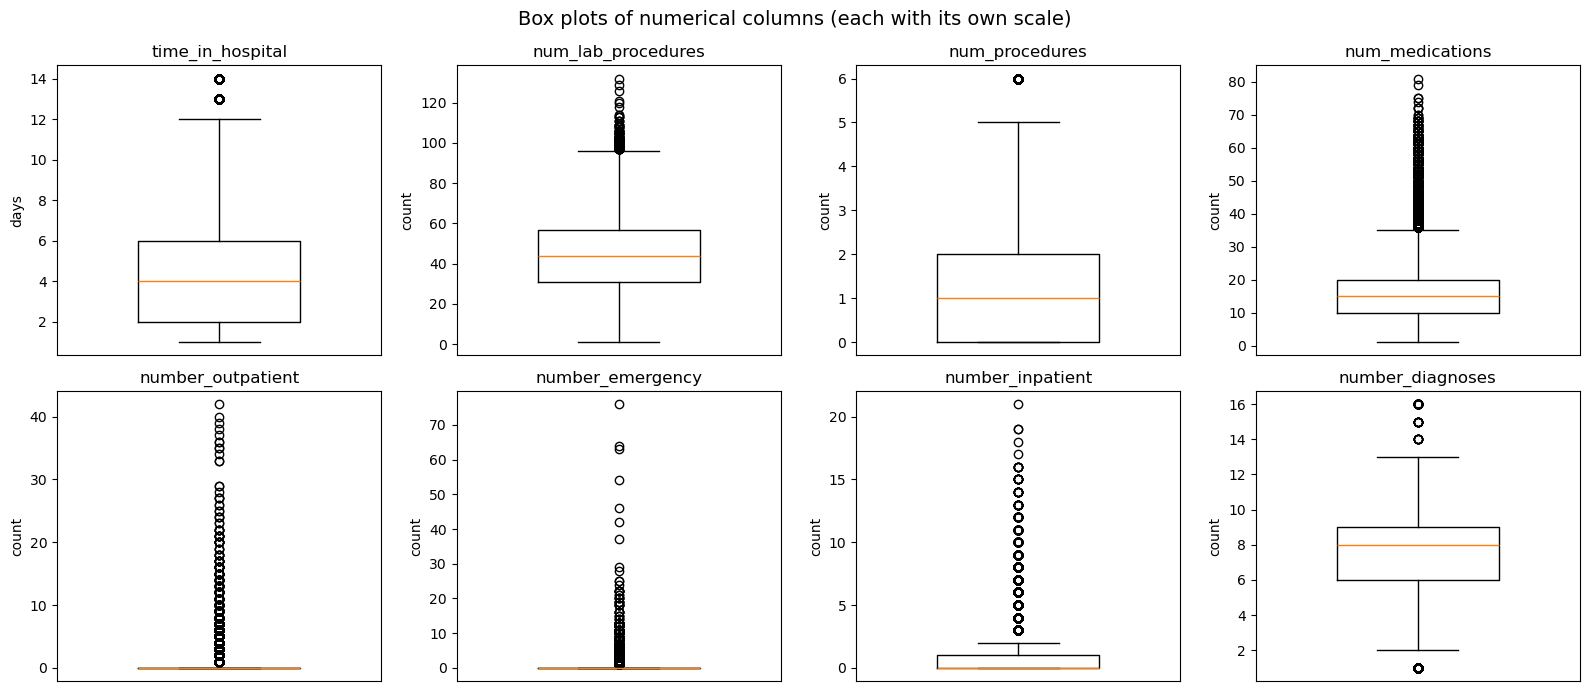

,count,mean,std,min,50%,90%,99%,max
number_outpatient,101766.0,0.369357,1.267265,0.0,0.0,1.0,5.0,42.0
number_emergency,101766.0,0.197836,0.930472,0.0,0.0,1.0,3.0,76.0
number_inpatient,101766.0,0.635566,1.262863,0.0,0.0,2.0,6.0,21.0


In [37]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), numeric_cols):
    ax.boxplot(df[col], widths=0.5)   # one box per subplot, so each column keeps its own scale
    ax.set_title(col)
    ax.set_xticks([])
    ax.set_ylabel("days" if col == "time_in_hospital" else "count")
fig.suptitle("Box plots of numerical columns (each with its own scale)", fontsize=14)
plt.tight_layout()
plt.show()

df[["number_outpatient", "number_emergency", "number_inpatient"]].describe(percentiles=[0.5, 0.9, 0.99]).T

**Observations:**
- As we can see in the boxplots of `num_lab_procedures` and `num_medications`, the outliers (above 97 and 35 respectively) forms a seamless tail, not some separated points. This suggests that these outliers are "real but rare" data, not errors.
- Because Q1 = Q3 = 0 for `number_outpatient` and `number_emergency`, the **IQR rule flags every non-zero value as an outlier** (16,739 and 11,383 rows), so it is not a meaningful rule for these columns. The extreme values (e.g. 76 emergency visits) are rare but realistic for frequent hospital users, so we **keep them** as genuine values, and consider a log transform or bins (0 / 1 / 2+) later.
- `time_in_hospital` 13-14 days and `number_diagnoses` 1 time is considered outliers, but they are still in plausible range, so we do not remove these samples.
- What impresses us the most when observing the boxplots is that in the `number_emergency` plot, there are some separated point in the outlier area. So we make a check for these samples.

In [39]:
df[df["number_emergency"] >= 30][["patient_nbr", "number_emergency", "time_in_hospital", "readmitted"]]

,patient_nbr,number_emergency,time_in_hospital,readmitted
32661,42466248,42,3,>30
77142,36645885,46,3,>30
83844,36645885,76,2,>30
86135,90847035,37,1,NO
88079,36645885,64,1,<30
88897,36645885,63,4,>30
94341,36645885,54,2,>30


As we can observe, 5 of the 7 encounters with ≥ 30 emergency visits belong to one patient. These values are extreme but consistent across that patient's encounters, so they are more likely a real frequent user than a random entry error. We keep them, and they show why rows of the same patient are not independent.

### 4. Categorical columns

In [40]:
categorical_summary(df, categorical_cols + code_cols)

,n_unique,top,top_pct,n_rare
race,5,Caucasian,76.49,1
gender,3,Female,53.76,1
age,10,[70-80),25.62,2
weight,9,[75-100),41.79,2
payer_code,17,MC,52.74,8
medical_specialty,72,InternalMedicine,28.24,56
max_glu_serum,4,None,94.75,0
A1Cresult,4,None,83.28,0
change,2,No,53.80,0
diabetesMed,2,Yes,77.00,0


Check every label of the low-cardinality columns for typos, inconsistent spelling and placeholder values:

In [42]:
for col in ["race", "gender", "age", "weight", "payer_code", "max_glu_serum", "A1Cresult", "change", "diabetesMed", target_col]:
    print(f"{col}: {df[col].value_counts(dropna=False).to_dict()}")

race: {'Caucasian': 76099, 'AfricanAmerican': 19210, nan: 2273, 'Hispanic': 2037, 'Other': 1506, 'Asian': 641}
gender: {'Female': 54708, 'Male': 47055, 'Unknown/Invalid': 3}
age: {'[70-80)': 26068, '[60-70)': 22483, '[50-60)': 17256, '[80-90)': 17197, '[40-50)': 9685, '[30-40)': 3775, '[90-100)': 2793, '[20-30)': 1657, '[10-20)': 691, '[0-10)': 161}
weight: {nan: 98569, '[75-100)': 1336, '[50-75)': 897, '[100-125)': 625, '[125-150)': 145, '[25-50)': 97, '[0-25)': 48, '[150-175)': 35, '[175-200)': 11, '>200': 3}
payer_code: {nan: 40256, 'MC': 32439, 'HM': 6274, 'SP': 5007, 'BC': 4655, 'MD': 3532, 'CP': 2533, 'UN': 2448, 'CM': 1937, 'OG': 1033, 'PO': 592, 'DM': 549, 'CH': 146, 'WC': 135, 'OT': 95, 'MP': 79, 'SI': 55, 'FR': 1}
max_glu_serum: {'None': 96420, 'Norm': 2597, '>200': 1485, '>300': 1264}
A1Cresult: {'None': 84748, '>8': 8216, 'Norm': 4990, '>7': 3812}
change: {'No': 54755, 'Ch': 47011}
diabetesMed: {'Yes': 78363, 'No': 23403}
readmitted: {'NO': 54864, '>30': 35545, '<30': 11357

As we can observe, there are **no inconsistent labels or typos** as every column use one consistent spelling. The only unusual labels are the placeholders found earlier (`?` -> NaN, `Unknown/Invalid` in `gender` with 3 rows).

The id columns are codes; we translate them with `IDS_mapping.csv` to see what the codes mean:

In [43]:
for col in code_cols:
    counts = df[col].value_counts()
    table = pd.DataFrame({"label": id_maps[col].reindex(counts.index), "n": counts,
                          "pct": (counts / len(df) * 100).round(2)})
    print(f"\n{col}")
    display(table.head(10))


admission_type_id


,label,n,pct
admission_type_id,,,
1,Emergency,53990,53.05
3,Elective,18869,18.54
2,Urgent,18480,18.16
6,NULL,5291,5.20
5,Not Available,4785,4.70
8,Not Mapped,320,0.31
7,Trauma Center,21,0.02
4,Newborn,10,0.01



discharge_disposition_id


,label,n,pct
discharge_disposition_id,,,
1,Discharged to home,60234,59.19
3,Discharged/transferred to SNF,13954,13.71
6,Discharged/transferred to home with home healt...,12902,12.68
18,NULL,3691,3.63
2,Discharged/transferred to another short term h...,2128,2.09
22,Discharged/transferred to another rehab fac in...,1993,1.96
11,Expired,1642,1.61
5,Discharged/transferred to another type of inpa...,1184,1.16
25,Not Mapped,989,0.97



admission_source_id


,label,n,pct
admission_source_id,,,
7,Emergency Room,57494,56.50
1,Physician Referral,29565,29.05
17,NULL,6781,6.66
4,Transfer from a hospital,3187,3.13
6,Transfer from another health care facility,2264,2.22
2,Clinic Referral,1104,1.08
5,Transfer from a Skilled Nursing Facility (SNF),855,0.84
3,HMO Referral,187,0.18
20,Not Mapped,161,0.16


Medication columns: most of them barely vary. In particular, all of these features have at most four values: `No`/`Steady`/`Up`/`Down`, so we summarise them in one table instead of one chart each.

In [44]:
med_summary = pd.DataFrame({
    "pct_No": (df[medication_cols] == "No").mean() * 100,
    "n_unique": df[medication_cols].nunique(),
}).round(2).sort_values("pct_No")
med_summary

,pct_No,n_unique
insulin,46.56,4
metformin,80.36,4
glipizide,87.53,4
glyburide,89.53,4
pioglitazone,92.80,4
rosiglitazone,93.75,4
glimepiride,94.90,4
repaglinide,98.49,4
nateglinide,99.31,4
glyburide-metformin,99.31,4


Diagnoses have hundreds of ICD-9 codes, so we group them into disease groups:

In [45]:
print("Distinct codes:", {c: df[c].nunique() for c in diag_cols})
diag_groups = df[diag_cols].apply(lambda s: s.map(icd9_group))
diag_groups.apply(lambda s: s.value_counts(normalize=True).mul(100).round(1))

Distinct codes: {'diag_1': 716, 'diag_2': 748, 'diag_3': 789}


,diag_1,diag_2,diag_3
Circulatory,29.9,31.3,29.8
Diabetes,8.6,12.6,16.9
Digestive,9.3,4.1,3.9
Genitourinary,5.0,8.2,6.6
Injury,6.9,2.4,1.9
Missing,0.0,0.4,1.4
Musculoskeletal,4.9,1.7,1.9
Neoplasms,3.4,2.5,1.8
Other,17.9,26.1,28.7
Respiratory,14.2,10.7,7.2


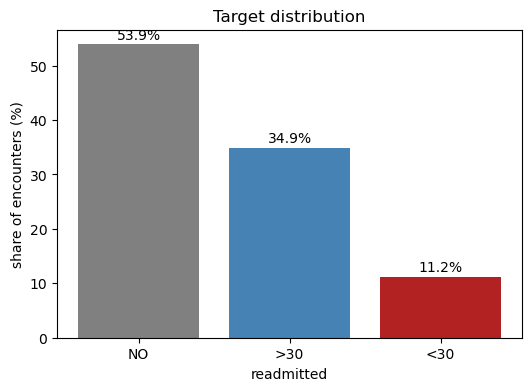

In [46]:
target_pct = df[target_col].value_counts(normalize=True).mul(100).reindex(["NO", ">30", "<30"])
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(target_pct.index, target_pct.values, color=["grey", "steelblue", "firebrick"])
for i, v in enumerate(target_pct.values):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center")
ax.set_xlabel("readmitted")
ax.set_ylabel("share of encounters (%)")
ax.set_title("Target distribution")
plt.show()

**Observations:**
- **Imbalanced demographics**: We can see in the `race` distribution that the data is dominated by `Caucasian` (76.49%), and patients are mostly old (81.6% of encounters are aged 50-90), while patients under 30 are only 2.5%
- `weight` is almost empty (96.86% missing), so it obviously cannot be used. `payer_code`(39.56% missing, 17 codes) and `medical specialty` (49.08% missing, 72 values, 56 of them under 1%) needs a `Missing` category and grouping of rare values.
- **Lab tests are rarely done**: `max_glu_serum` is None (not tested) in 94.75% of encounters and A1Cresult in 83.28%. Therefore, "Tested or not" may be more informative than the result itself.
- **Id columns hide unknown values and rare codes**: `admission_type_id` has 10.2% `NULL` / `Not Available` / `Not Mapped`, and very rare codes such as `Newborn` (10) and `Trauma Center` (21). `discharge_disposition_id` has 26 codes, 18 of them under 1%. These should be translated with IDS_mapping.csv and grouped (e.g. home / transferred / expired / unknown). Encounters discharged as Expired (1.6%) cannot be readmitted and should be excluded.
- **Most medication columns carry almost no information**: apart from insulin (53.44% used) and metformin (19.64%), every drug is No in over 87% of encounters, and `examide` and `citoglipton` have a single value. Constant and near-constant columns can be dropped, or summarised into derived variables (number of drugs used, any dose change).
- For `diag_*` features, after grouping, Circulatory is the largest group (about 30% in each position), while Diabetes is the primary diagnosis in only 8.6% of encounters: patients are mostly hospitalised for other conditions.
- Finally, regarding the target, we can see the imbalance: `NO` 53.9%, `>30` 34.9%, `<30` 11.2%. For a 30-day readmission task the positive class is only about 11%, so accuracy would be misleading and we need a metric such as recall, F1 or PR-AUC.

## 4. Missing data

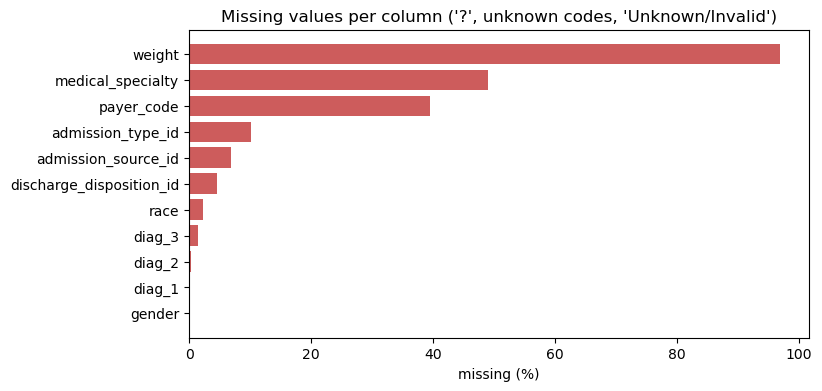

,n_missing,pct_missing
weight,98569,96.86
medical_specialty,49949,49.08
payer_code,40256,39.56
admission_type_id,10396,10.22
admission_source_id,7067,6.94
discharge_disposition_id,4680,4.60
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


In [47]:
missing = missing_table(df)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(missing.index, missing["pct_missing"], color="indianred")
ax.invert_yaxis()
ax.set_xlabel("missing (%)")
ax.set_title("Missing values per column ('?', unknown codes, 'Unknown/Invalid')")
plt.show()
missing

Is missingness random? We compare the 30-day readmission rate between rows with and without a missing value:

In [48]:
df["readmit_30"] = (df[target_col] == "<30").astype(int)
rows = {}
for col in ["weight", "medical_specialty", "payer_code", "race"]:
    is_missing = df[col].isna()
    rows[col] = {"rate_if_missing": df.loc[is_missing, "readmit_30"].mean() * 100,
                 "rate_if_present": df.loc[~is_missing, "readmit_30"].mean() * 100}
pd.DataFrame(rows).T.round(2)

,rate_if_missing,rate_if_present
weight,11.16,11.17
medical_specialty,11.57,10.76
payer_code,11.49,10.94
race,8.27,11.23


Do columns tend to be missing together?

In [49]:
df[["weight", "medical_specialty", "payer_code", "race"]].isna().astype(int).corr().round(2)

,weight,medical_specialty,payer_code,race
weight,1.00,0.00,0.04,-0.03
medical_specialty,0.00,1.00,-0.14,0.01
payer_code,0.04,-0.14,1.00,-0.05
race,-0.03,0.01,-0.05,1.00


Encounters that ended in death or hospice cannot be readmitted, so they are not really part of the population at risk:

In [50]:
expired = df["discharge_disposition_id"].isin(EXPIRED_OR_HOSPICE_CODES)
print(f"Expired / hospice encounters: {expired.sum():,} ({expired.mean():.2%})")
print(df.loc[expired, target_col].value_counts().to_dict())

Expired / hospice encounters: 2,423 (2.38%)
{'NO': 2337, '<30': 43, '>30': 43}
